In [1]:
# Import libraries
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Load and prepare the dataset
df = pd.read_csv("../data/ai4i2020.csv")

columns_to_drop = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

X = df.drop(columns=columns_to_drop + ["Machine failure"])
X = pd.get_dummies(X, columns=["Type"], dtype=int)
y = df["Machine failure"]

# Split the data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# Train models and collect evaluation metrics
results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_scores = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "PR-AUC (Average Precision)": average_precision_score(
            y_test, y_scores
        )
    })

    trained_models[name] = model

# Display comparison
results_df = pd.DataFrame(results).set_index("Model")

print("Model Comparison:")
print(results_df.round(3).to_string())

Model Comparison:
                     Accuracy  Precision  Recall  F1-score  PR-AUC (Average Precision)
Model                                                                                 
Logistic Regression     0.827      0.144   0.824     0.245                       0.396
Decision Tree           0.953      0.404   0.809     0.539                       0.658
Random Forest           0.979      0.906   0.426     0.580                       0.773


In [2]:
# Compare actual and predicted failure counts
from sklearn.metrics import confusion_matrix

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    print(f"\n{name}")
    print(f"True Negatives:  {tn}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Positives:  {tp}")


Logistic Regression
True Negatives:  1598
False Positives: 334
False Negatives: 12
True Positives:  56

Decision Tree
True Negatives:  1851
False Positives: 81
False Negatives: 13
True Positives:  55

Random Forest
True Negatives:  1929
False Positives: 3
False Negatives: 39
True Positives:  29


In [3]:
# Import evaluation tools
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score
)

# Create training, validation, and test sets
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

# Train Random Forest on the training subset
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_fit, y_train_fit)

# Select a threshold that achieves at least 80% recall on validation data
val_scores = rf_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, val_scores
)

# The last precision and recall values have no corresponding threshold
valid_indices = [
    i for i, threshold in enumerate(thresholds)
    if recall[i] >= 0.80
]

if valid_indices:
    best_index = max(
        valid_indices,
        key=lambda i: precision[i]
    )
    selected_threshold = thresholds[best_index]

    print(f"Selected threshold: {selected_threshold:.3f}")
    print(f"Validation precision: {precision[best_index]:.3f}")
    print(f"Validation recall: {recall[best_index]:.3f}")

    # Evaluate the selected threshold on the untouched test set
    test_scores = rf_model.predict_proba(X_test)[:, 1]
    test_pred = (test_scores >= selected_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, test_pred, labels=[0, 1]
    ).ravel()

    print("\nTest Results:")
    print(f"Precision: {precision_score(y_test, test_pred, zero_division=0):.3f}")
    print(f"Recall: {recall_score(y_test, test_pred, zero_division=0):.3f}")
    print(f"F1-score: {f1_score(y_test, test_pred, zero_division=0):.3f}")
    print(f"PR-AUC: {average_precision_score(y_test, test_scores):.3f}")
    print(f"True Positives: {tp}")
    print(f"False Positives: {fp}")
    print(f"True Negatives: {tn}")
    print(f"False Negatives: {fn}")

else:
    print("No threshold achieved the target recall on validation data.")

Selected threshold: 0.100
Validation precision: 0.364
Validation recall: 0.815

Test Results:
Precision: 0.392
Recall: 0.853
F1-score: 0.537
PR-AUC: 0.724
True Positives: 58
False Positives: 90
True Negatives: 1842
False Negatives: 10


In [4]:
# Extract and rank Random Forest feature importances
feature_importance = pd.DataFrame({
    "Feature": X_train_fit.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
print(feature_importance.round(4).to_string(index=False))

Random Forest Feature Importance:
                Feature  Importance
 Rotational speed [rpm]      0.3076
            Torque [Nm]      0.2891
        Tool wear [min]      0.1870
    Air temperature [K]      0.1163
Process temperature [K]      0.0805
                 Type_L      0.0077
                 Type_M      0.0067
                 Type_H      0.0050


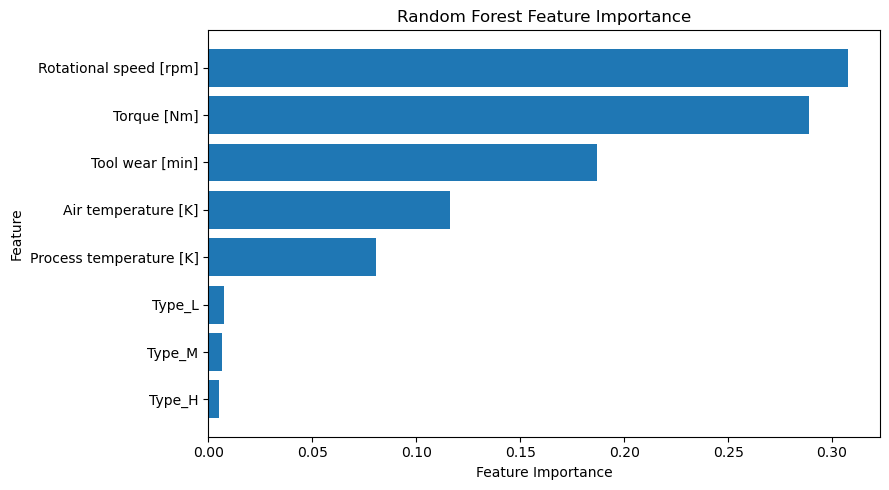

In [5]:

# Visualize Random Forest feature importance
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()

plt.savefig(
    "../reports/figures/random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


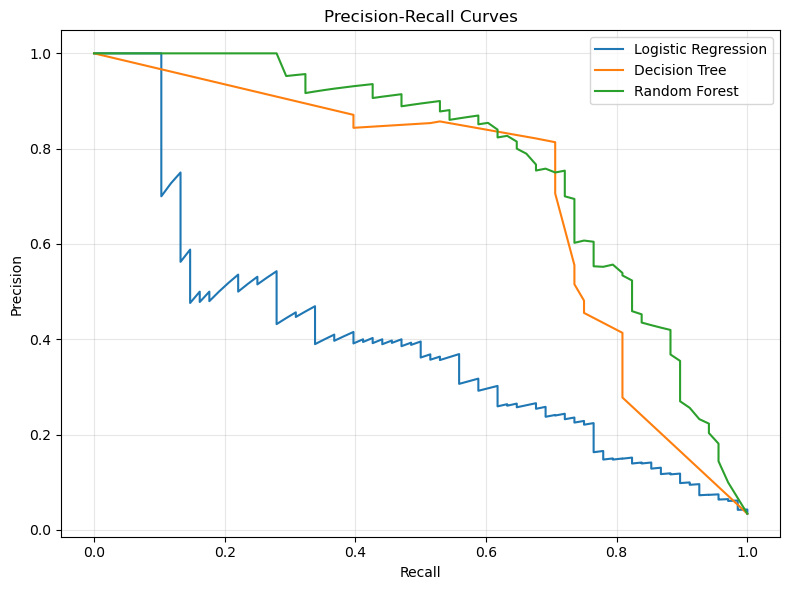

In [6]:

# Compare Precision-Recall curves for all models
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_scores = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_scores)

    plt.plot(recall, precision, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


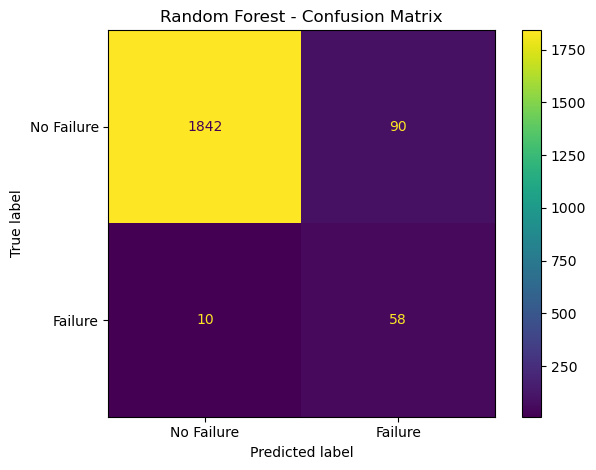

In [7]:

# Analyze Random Forest predictions at the selected threshold
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use the threshold selected earlier
y_scores = rf_model.predict_proba(X_test)[:, 1]
y_pred_threshold = (y_scores >= selected_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_threshold,
    display_labels=["No Failure", "Failure"],
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "../reports/figures/random_forest_tuned_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [8]:

# Save model comparison results
results_df = pd.DataFrame(results)

results_df.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

results_df


,Model,Accuracy,Precision,Recall,F1-score,PR-AUC (Average Precision)
0,Logistic Regression,0.827,0.143590,0.823529,0.244541,0.396317
1,Decision Tree,0.953,0.404412,0.808824,0.539216,0.657828
2,Random Forest,0.979,0.906250,0.426471,0.580000,0.772695


In [9]:

# Inspect failures missed by the tuned Random Forest
error_analysis = X_test.copy()

error_analysis["Actual Failure"] = y_test
error_analysis["Predicted Failure"] = y_pred_threshold

# Select actual failures that the model missed
missed_failures = error_analysis[
    (error_analysis["Actual Failure"] == 1) &
    (error_analysis["Predicted Failure"] == 0)
]

print("Number of missed failures:", len(missed_failures))
display(missed_failures.head(10))


Number of missed failures: 10


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M,Actual Failure,Predicted Failure
7884,300.8,312.4,1465,59.1,91,0,1,0,1,0
9174,297.8,308.9,1871,25.6,200,0,1,0,1,0
2671,299.7,309.3,1399,41.9,221,0,0,1,1,0
3695,302.2,311.3,1530,37.3,207,0,1,0,1,0
7087,300.6,310.3,1648,30.5,217,0,1,0,1,0
2941,300.7,309.6,1996,19.8,203,0,0,1,1,0
7849,300.3,311.7,1374,47.9,222,0,0,1,1,0
8506,298.4,309.6,1710,27.3,163,0,1,0,1,0
1996,298.4,308.0,1416,38.2,198,0,0,1,1,0
4034,302.0,310.8,1615,29.0,235,0,1,0,1,0


In [10]:

# Count each type of prediction error
print("Missed failures (FN):",
      ((error_analysis["Actual Failure"] == 1) &
       (error_analysis["Predicted Failure"] == 0)).sum())

print("False alarms (FP):",
      ((error_analysis["Actual Failure"] == 0) &
       (error_analysis["Predicted Failure"] == 1)).sum())


Missed failures (FN): 10
False alarms (FP): 90


In [12]:

# Save the tuned Random Forest error analysis
error_analysis.to_csv(
    "../reports/tuned_random_forest_predictions.csv",
    index=True,
    index_label="Test Index"
)
